# 01 · The stability of a forecast service, in closed form

**Block 4 · W44.** Blocks 2 and 5 *measure* what a retraining cadence costs and buys. This notebook *explains*
it, on the simplest model where every quantity has a formula: a level that wanders, observed with noise, and
served as the mean of the last `w` observations, refreshed every `k` steps.

| § | Question | Short answer |
|---|---|---|
| 1 | What is the model, and what does a window mean really estimate? | The level **(w - 1)/2 steps in the past**: the centroid lag. |
| 2 | Where does the forecast error come from? | Four additive terms: target noise, estimation noise, centroid lag, model age. |
| 3 | Which window is best, and does it depend on the cadence? | `w* = sqrt(3 (sigma^2 + q/6) / q)`, the same for every `k`. |
| 4 | Can we trust the formulas? | Monte Carlo agrees within its own standard error. |
| 5 | What is a published revision made of? | Estimation jitter (noise) plus real level drift (information). |
| 6 | Does rare retraining reduce churn? | It concentrates it in large jumps; churn per step falls slowly, with no hard floor. |
| 7 | How do we choose `k` when stability has a price? | Minimise `MSE + lambda * churn`; the window is the bigger lever. |
| 8 | Can a tighter cron fix a biased model? | No: under a trend, most of the bias is window bias, which no cadence touches. |

> **How to read this notebook.** The boxed notes follow a fixed code:
> **Intuition**, the idea without equations · **Example**, a computed experiment ·
> **Watch out**, the trap to avoid · **Takeaway**, the memo to keep.

In [1]:
import logging

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from w44_retraining import fundamentals as F
from w44_retraining import viz

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
viz.setup()
export = viz.exporter("../figures")


def table(rows, cols, fmt="{:.4f}"):
    """Render a list of row tuples as a Markdown table (numbers formatted with fmt)."""
    cell = lambda v: fmt.format(v) if isinstance(v, float) else str(v)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(cell(v) for v in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

SIG, Q, W = 1.0, 0.004, 240      # noise std, level-increment variance, the window used in blocks 2 and 5

## 1. The model, and what a window mean estimates

**Notation.** At each step $t$ we observe $y_t = L_t + e_t$:

- $L_t$ is the true **level**, a random walk: $L_t = L_{t-1} + u_t$ with $u_t \sim \mathcal N(0, q)$. It is
  what we want to forecast. $q$ says how fast the world drifts.
- $e_t \sim \mathcal N(0, \sigma^2)$ is **observation noise**, independent of everything.

The service publishes $\hat\mu$, the mean of the last $w$ observations, and **re-estimates it every $k$
steps**. Between two re-estimations it keeps serving the same number, so the served model has an **age**
$a \in \{0, \dots, k-1\}$, of mean $\bar a = (k-1)/2$. Here $\sigma = 1$ and $q = 0.004$: in 250 steps the level
moves by about one noise standard deviation.

> **Intuition.** A window mean is a compromise. A long window averages out the noise but remembers an old
> level; a short window is up to date but noisy. And between refits, the world keeps moving while the published
> number stays still.

### Example: the centroid lag, made visible

Take a level that rises steadily ($L_t = 0.01\,t$) and a window of $w = 100$. The window mean is exactly the
level at the **middle** of the window, $(w-1)/2 = 49.5$ steps in the past, not the level now.

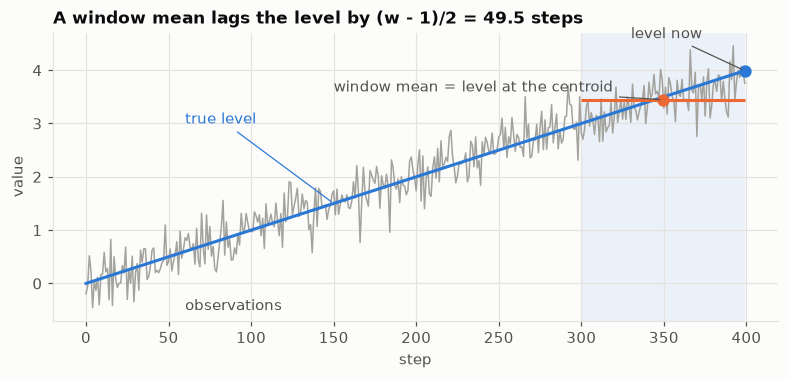

window mean 3.444 | level at the centroid 3.495 | level now 3.990


In [2]:
rng = np.random.default_rng(4)
t = np.arange(400)
level = 0.01 * t
y = level + rng.normal(0, 0.3, t.size)
w_demo, t_end = 100, 399
mean = y[t_end - w_demo + 1 : t_end + 1].mean()
centroid = t_end - (w_demo - 1) / 2

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(t, y, color=viz.MUTED, lw=1)
ax.plot(t, level, color=viz.BLUE)
ax.axvspan(t_end - w_demo + 1, t_end, color=viz.BLUE, alpha=0.08, lw=0)
ax.hlines(mean, t_end - w_demo + 1, t_end, color=viz.ORANGE)
ax.scatter([centroid], [mean], color=viz.ORANGE, s=50, zorder=3)
ax.scatter([t_end], [level[t_end]], color=viz.BLUE, s=50, zorder=3)
ax.annotate("window mean = level at the centroid", (centroid, mean), (150, 3.6), color=viz.TEXT_2,
            arrowprops=dict(arrowstyle="-", color=viz.TEXT_2, lw=0.8))
ax.annotate("level now", (t_end, level[t_end]), (330, 4.6), color=viz.TEXT_2,
            arrowprops=dict(arrowstyle="-", color=viz.TEXT_2, lw=0.8))
ax.annotate("true level", (150, 1.5), (60, 3.0), color=viz.BLUE,
            arrowprops=dict(arrowstyle="-", color=viz.BLUE, lw=0.8))
ax.text(60, -0.5, "observations", color=viz.TEXT_2)
ax.set_xlabel("step"); ax.set_ylabel("value")
ax.set_title(f"A window mean lags the level by (w - 1)/2 = {(w_demo - 1) / 2:.1f} steps")
export(fig, "centroid_lag"); plt.show()
print(f"window mean {mean:.3f} | level at the centroid {0.01 * centroid:.3f} | level now {level[t_end]:.3f}")

## 2. Where the forecast error comes from: four additive terms

The one-step error of the served mean, at age $a$, is
$y_{t+1} - \hat\mu = e_{t+1} + (L_{t+1} - \bar L_{\text{window}}) - \bar e_{\text{window}}$.
The three pieces are independent, so their variances add:

1. **Target noise** $\sigma^2$: the new observation is noisy. No model removes it.
2. **Estimation noise** $\sigma^2 / w$: the window mean of $w$ noises.
3. **Centroid lag** $q\,(w-1)(2w-1)/(6w)$: the level drifted while the window was being collected. It comes from
   $\mathrm{Var}\big[\tfrac1w \sum_j (L_{\text{end}} - L_j)\big]$ and the identity
   $\sum_{j,j'} \min(j, j') = (w-1)w(2w-1)/6$.
4. **Model age** $q\,(a+1)$: the level keeps drifting after the fit, one increment per step.

Averaging over the age gives the closed form

$$\mathrm{MSE}(k, w) = \sigma^2\Big(1 + \frac1w\Big) + q\Big[(\bar a + 1) + \frac{(w-1)(2w-1)}{6w}\Big],
\qquad \bar a = \frac{k-1}{2}.$$

### Example: the four terms for the configurations of blocks 2 and 5

In [3]:
rows = []
for k, w in ((1, 240), (24, 240), (168, 240), (24, 27)):
    p = F.mse_parts(k, w, SIG, Q)
    rows.append((f"k={k}, w={w}", *p.values(), sum(p.values())))
table(rows, ["config", "target noise", "estimation", "centroid lag", "model age", "MSE"])

| config | target noise | estimation | centroid lag | model age | MSE |
|---|---|---|---|---|---|
| k=1, w=240 | 1.0000 | 0.0042 | 0.3180 | 0.0040 | 1.3262 |
| k=24, w=240 | 1.0000 | 0.0042 | 0.3180 | 0.0500 | 1.3722 |
| k=168, w=240 | 1.0000 | 0.0042 | 0.3180 | 0.3380 | 1.6602 |
| k=24, w=27 | 1.0000 | 0.0370 | 0.0340 | 0.0500 | 1.1211 |

> **Watch out.** With $w = 240$ the **centroid lag** (0.318) is six times the **model age** at a daily cadence
> (0.050), and still about equal to it at a weekly cadence (0.338). In this configuration the window is the
> dominant error source after the irreducible noise, and it is not a cadence problem. With $w = 27$ the same
> daily service drops from 1.372 to 1.121.

## 3. The best window does not depend on the cadence

Only two terms depend on $w$: $\sigma^2/w$ falls with $w$, the centroid lag grows with it. Setting the derivative
to zero gives an interior optimum,

$$w^* = \sqrt{\frac{3(\sigma^2 + q/6)}{q}} \approx \sigma\sqrt{3/q},$$

and **$k$ does not appear**: the age term $q(\bar a + 1)$ does not involve $w$. Changing the cadence shifts the
whole MSE curve up or down; it never moves its minimum.

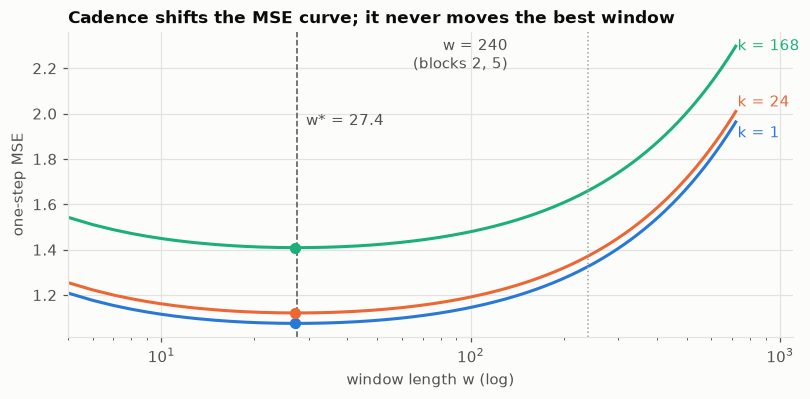

numerical argmin over w: {1: 27, 24: 27, 168: 27}


In [4]:
ws = np.arange(5, 721)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for k, color in ((1, viz.BLUE), (24, viz.ORANGE), (168, viz.AQUA)):
    mse = np.array([F.mse_closed(k, w, SIG, Q) for w in ws])
    ax.plot(ws, mse, color=color)
    i = mse.argmin()
    ax.scatter([ws[i]], [mse[i]], color=color, s=40, zorder=3)
    ax.text(730, mse[-1] + {1: -0.05, 24: 0.04, 168: 0.0}[k], f"k = {k}", color=color, va="center")
ax.axvline(F.w_star(SIG, Q), color=viz.TEXT_2, ls="--", lw=1)
ax.text(F.w_star(SIG, Q) + 2, 1.95, f"w* = {F.w_star(SIG, Q):.1f}", color=viz.TEXT_2)
ax.axvline(W, color=viz.MUTED, ls=":", lw=1)
ax.text(W * 0.55, 2.2, "w = 240\n(blocks 2, 5)", color=viz.TEXT_2, ha="right")
ax.set_xscale("log"); ax.set_xlim(5, 1100)
ax.set_xlabel("window length w (log)"); ax.set_ylabel("one-step MSE")
ax.set_title("Cadence shifts the MSE curve; it never moves the best window")
export(fig, "mse_vs_window"); plt.show()
print("numerical argmin over w:", {k: min(range(3, 600), key=lambda w, k=k: F.mse_closed(k, w, SIG, Q))
                                   for k in (1, 24, 168)})

> **Takeaway.** Window length fixes the window bias, cadence fixes the model age. They are two additive terms
> and two separate knobs. Tightening the cron does nothing for a window that is too long.

## 4. Can we trust the formulas? Monte Carlo, with error bars

A closed form that has not been confronted with a simulation is a conjecture (the plan's appendix reports that
its first draft was wrong by a factor 17 on $\mathrm{Var}(R)$, caught only this way). We simulate 300,000 steps of the process, serve the
window mean exactly as the service would, and compare. To know whether a gap is a defect of the formula or
simulation noise, we repeat with 5 seeds and use their spread as the standard error.

| k | w | MSE gap (5 seeds) | MSE 2 s.e. | Var(R) gap (5 seeds) | Var(R) 2 s.e. |
|---|---|---|---|---|---|
| 1 | 20 | -0.03% | 0.25% | -0.08% | 0.37% |
| 1 | 100 | -0.12% | 0.24% | -0.16% | 0.37% |
| 10 | 100 | -0.13% | 0.25% | -0.73% | 0.99% |
| 50 | 100 | -0.24% | 0.36% | -1.36% | 1.66% |
| 100 | 100 | -0.35% | 0.57% | -1.60% | 2.17% |
| 200 | 100 | -0.36% | 0.83% | -0.96% | 2.23% |
| 24 | 240 | -0.32% | 0.74% | -0.97% | 2.36% |
| 168 | 240 | -0.50% | 1.07% | -0.91% | 2.62% |

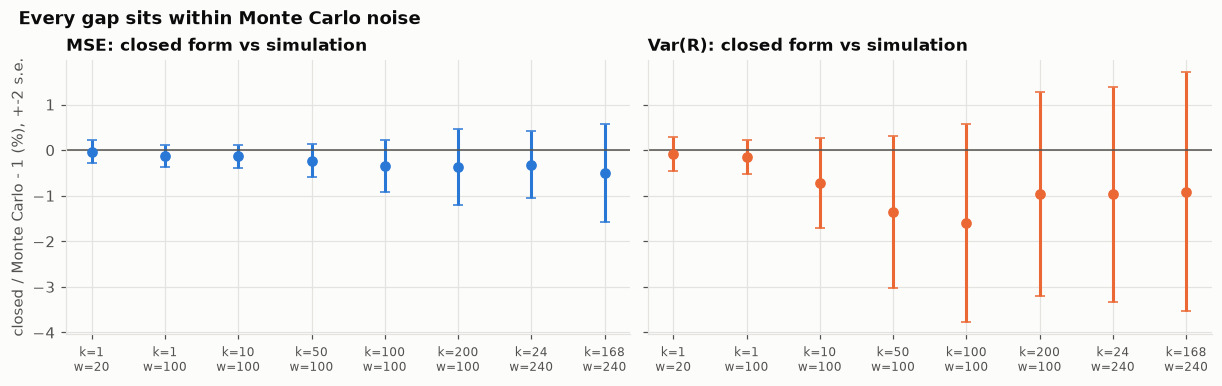

In [5]:
seeds = (44, 45, 46, 47, 48)
recs = []
for k, w in F.MC_CONFIGS:
    sims = np.array([F.monte_carlo(k, w, SIG, Q, seed=s) for s in seeds])
    for j, (name, closed) in enumerate((("MSE", F.mse_closed(k, w, SIG, Q)), ("Var(R)", F.var_revision(k, w, SIG, Q)))):
        m, se = sims[:, j].mean(), sims[:, j].std(ddof=1) / np.sqrt(len(seeds))
        recs.append(dict(k=k, w=w, quantity=name, closed=closed, mc_mean=m, gap=closed / m - 1, two_se=2 * se / m))
mse_r, var_r = recs[0::2], recs[1::2]
table([(a["k"], a["w"], f"{a['gap']:+.2%}", f"{a['two_se']:.2%}", f"{b['gap']:+.2%}", f"{b['two_se']:.2%}")
       for a, b in zip(mse_r, var_r, strict=True)],
      ["k", "w", "MSE gap (5 seeds)", "MSE 2 s.e.", "Var(R) gap (5 seeds)", "Var(R) 2 s.e."])

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), layout="constrained", sharey=True)
for ax, name, color in zip(axs, ("MSE", "Var(R)"), (viz.BLUE, viz.ORANGE), strict=True):
    sub = [r for r in recs if r["quantity"] == name]
    labels = [f"k={r['k']}\nw={r['w']}" for r in sub]
    ax.errorbar(range(len(sub)), [100 * r["gap"] for r in sub], yerr=[100 * r["two_se"] for r in sub],
                fmt="o", color=color, ms=6, capsize=3)
    ax.axhline(0, color=viz.TEXT_2, lw=1)
    ax.set_xticks(range(len(sub)), labels, fontsize=8)
    ax.set_title(f"{name}: closed form vs simulation")
axs[0].set_ylabel("closed / Monte Carlo - 1 (%), +-2 s.e.")
fig.suptitle("Every gap sits within Monte Carlo noise", x=0.01, ha="left", fontweight="semibold")
export(fig, "mc_validation"); plt.show()

> **Example.** The largest single-seed gap on $\mathrm{Var}(R)$ in the plan was 1.8% (k = 168, w = 240). With
> only about 1,800 revisions in 300,000 steps at that cadence, the simulated variance is itself uncertain by a few
> percent. Averaged over 5 seeds, every gap is inside two standard errors: the formulas hold.

## 5. What a published revision is made of

Each re-estimation publishes a **revision** $R = \hat\mu_{\text{new}} - \hat\mu_{\text{old}}$. The two window
means share some observations (when $k < w$) and differ on the rest. Counting how many times each noise and
each level increment enters the difference (with $a = \min(k, w)$, $b = \max(k, w)$):

$$\mathrm{Var}(R) = \underbrace{\frac{2a\sigma^2}{w^2}}_{\text{estimation jitter}}
+ \underbrace{\frac{q}{w^2}\Big[a^2(b-a+1) + \frac{(a-1)a(2a-1)}{3}\Big]}_{\text{real level drift}}.$$

> **Intuition.** Publishing a revision says "the information changed". The drift part *is* information: the level
> really moved and the client should hear about it. The jitter part is noise we republish: it would average out
> if we waited. The **noise share** $= \text{jitter} / \mathrm{Var}(R)$ is the fraction of what we publish that
> carries no information. It is a measurable, signable property of a service.

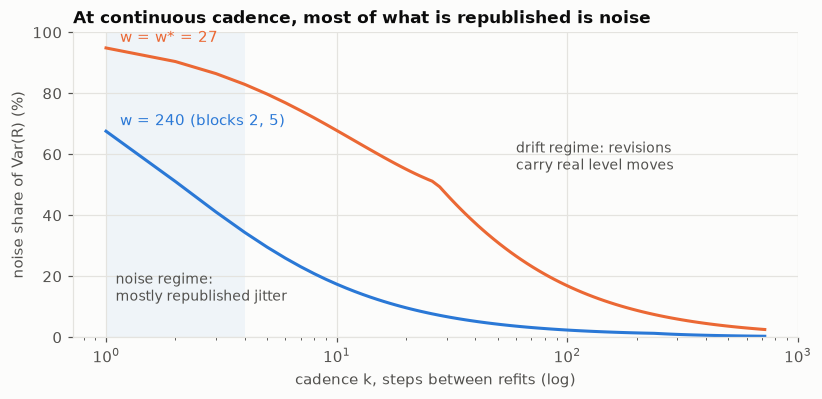

| k | E|R| (jump) | churn / step | x jump vs k=1 | x churn vs k=1 | noise share |
|---|---|---|---|---|---|
| 1 | 0.00572 | 0.005720 | 1.0x | 1.000x | 67.6% |
| 2 | 0.00930 | 0.004652 | 1.6x | 0.813x | 51.1% |
| 4 | 0.01604 | 0.004010 | 2.8x | 0.701x | 34.4% |
| 24 | 0.08024 | 0.003343 | 14.0x | 0.585x | 8.2% |
| 48 | 0.15453 | 0.003219 | 27.0x | 0.563x | 4.4% |
| 168 | 0.48302 | 0.002875 | 84.4x | 0.503x | 1.6% |
| 240 | 0.64245 | 0.002677 | 112.3x | 0.468x | 1.3% |
| 720 | 1.27869 | 0.001776 | 223.6x | 0.310x | 0.3% |

noise share at k = 1: w = 240 -> 67.6% | w = 27 -> 94.9%


In [6]:
ks = np.unique(np.round(np.logspace(0, np.log10(720), 120)).astype(int))
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for w, color, label in ((W, viz.BLUE, "w = 240 (blocks 2, 5)"), (27, viz.ORANGE, "w = w* = 27")):
    share = [100 * F.noise_share(k, w, SIG, Q) for k in ks]
    ax.plot(ks, share, color=color)
    ax.text(1.15, share[0] + 2, label, color=color)
ax.axvspan(1, 4, color=viz.BLUE, alpha=0.06, lw=0)
ax.text(1.1, 12, "noise regime:\nmostly republished jitter", color=viz.TEXT_2, fontsize=9)
ax.text(60, 55, "drift regime: revisions\ncarry real level moves", color=viz.TEXT_2, fontsize=9)
ax.set_xscale("log"); ax.set_ylim(0, 100)
ax.set_xlabel("cadence k, steps between refits (log)"); ax.set_ylabel("noise share of Var(R) (%)")
ax.set_title("At continuous cadence, most of what is republished is noise")
export(fig, "noise_share"); plt.show()

st = F.study(SIG, Q, W, seeds=(44, 45))
table([(r["k"], f"{r['jump']:.5f}", f"{r['churn']:.6f}", f"{r['x_jump']:.1f}x", f"{r['x_churn']:.3f}x", f"{r['noise']:.1%}")
       for r in st["decomposition"]], ["k", "E|R| (jump)", "churn / step", "x jump vs k=1", "x churn vs k=1", "noise share"])
print(f"noise share at k = 1: w = 240 -> {F.noise_share(1, 240, SIG, Q):.1%} | w = 27 -> {F.noise_share(1, 27, SIG, Q):.1%}")

> **Watch out.** The often-quoted "two thirds of revisions are noise at continuous cadence" (67.6%) belongs to
> $w = 240$, nine times the optimal window. At $w^* \approx 27$ the share at $k = 1$ is 94.9%: the shorter the
> window, the more of what is republished is noise. Always quote the noise share **with its window**.

## 6. Does rare retraining reduce churn? It concentrates it

Two quantities, often confused:

- the **jump** $\mathbb E|R| = \sqrt{2/\pi}\,\sqrt{\mathrm{Var}(R)}$ ($R$ is Gaussian): what the client sees on a
  refit day;
- the **churn per step** $\mathbb E|R| / k$: the average revision per step, spread over the $k$ quiet steps.

From continuous to monthly ($k = 720$), the jump grows 223.6 times while churn per step only falls 3.2 times.

**The floor question.** For $1 \ll k \ll w$ the drift term dominates and $\mathrm{Var}(R) \approx q k^2 / w$, so
churn per step tends to the constant $\sqrt{2/\pi}\sqrt{q/w}$: the plan calls it a floor where cadence stops being
a lever. The exact formula says this plateau is only an asymptote:

- at $k = w$, $\mathrm{Var}(R) \approx \tfrac23 q w$, so churn is $\sqrt{2/3} \approx 0.82$ of the "floor";
- for $k > w$, $\mathrm{Var}(R) \approx q(k - w/3)$, so churn keeps falling, towards $\sqrt{2/\pi}\sqrt{q/k}$.

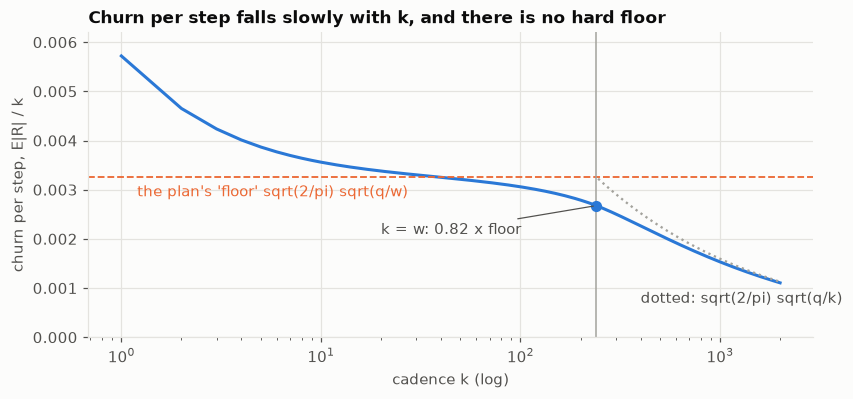

k =   1: jump E|R| = 0.00572  churn/step = 0.005720  (1.76 x floor)
k =  24: jump E|R| = 0.08024  churn/step = 0.003343  (1.03 x floor)
k = 240: jump E|R| = 0.64245  churn/step = 0.002677  (0.82 x floor)
k = 720: jump E|R| = 1.27869  churn/step = 0.001776  (0.55 x floor)


In [7]:
ks = np.unique(np.round(np.logspace(0, np.log10(2000), 200)).astype(int))
churn = np.array([F.churn_per_step(k, W, SIG, Q) for k in ks])
floor = F.SQ2PI * np.sqrt(Q / W)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(ks, churn, color=viz.BLUE)
ax.axhline(floor, color=viz.ORANGE, ls="--", lw=1.2)
ax.text(1.2, floor * 0.88, "the plan's 'floor' sqrt(2/pi) sqrt(q/w)", color=viz.ORANGE)
big = ks[ks > W]
ax.plot(big, F.SQ2PI * np.sqrt(Q / big), color=viz.MUTED, ls=":", lw=1.5)
ax.text(400, 0.0007, "dotted: sqrt(2/pi) sqrt(q/k)", color=viz.TEXT_2)
ax.axvline(W, color=viz.MUTED, lw=1)
ax.scatter([W], [F.churn_per_step(W, W, SIG, Q)], color=viz.BLUE, s=40, zorder=3)
ax.annotate(f"k = w: {F.churn_per_step(W, W, SIG, Q) / floor:.2f} x floor", (W, F.churn_per_step(W, W, SIG, Q)),
            (20, 0.0021), color=viz.TEXT_2, arrowprops=dict(arrowstyle="-", color=viz.TEXT_2, lw=0.8))
ax.set_xscale("log"); ax.set_ylim(0, 0.0062)
ax.set_xlabel("cadence k (log)"); ax.set_ylabel("churn per step, E|R| / k")
ax.set_title("Churn per step falls slowly with k, and there is no hard floor")
export(fig, "churn_regimes"); plt.show()
for k in (1, 24, 240, 720):
    print(f"k = {k:>3d}: jump E|R| = {F.mean_jump(k, W, SIG, Q):.5f}  churn/step = {F.churn_per_step(k, W, SIG, Q):.6f}"
          f"  ({F.churn_per_step(k, W, SIG, Q) / floor:.2f} x floor)")

> **Takeaway.** Retraining less does not remove churn, it **concentrates** it: rare, large jumps instead of
> frequent, small ones. Cadence remains a lever on churn per step, but a weak one (x0.47 from $k = 1$ to
> $k = w$). A service contract must say which of the two it limits: the size of a jump, or how often one is
> visible. Blocks 2 and 5 show that the two clauses pull in opposite directions.

## 7. Choosing k when stability has a price

Write the service objective $J = \mathrm{MSE}(k, w) + \lambda \cdot \text{churn per step}$, where $\lambda$ says
how much one unit of churn costs compared with one unit of squared error. With $w = 240$ fixed, the best $k$ jumps
from continuous to monthly as $\lambda$ grows; with $w$ free, the optimiser moves the **window** first.

In [8]:
table([(f"{r['lam']:.0f}", r["k"], r["mse"], f"{r['churn']:.6f}", f"{r['noise']:.1%}") for r in st["lambda_fixed_w"]],
      ["lambda", "best k (w = 240)", "MSE", "churn / step", "noise share"])
table([(f"{r['lam']:.0f}", r["k"], r["w"], r["mse"], f"{r['noise']:.1%}") for r in st["lambda_free_w"]],
      ["lambda", "best k", "best w", "MSE", "noise share"])

| lambda | best k (w = 240) | MSE | churn / step | noise share |
|---|---|---|---|---|
| 0 | 1 | 1.3262 | 0.005720 | 67.6% |
| 1 | 1 | 1.3262 | 0.005720 | 67.6% |
| 10 | 4 | 1.3322 | 0.004010 | 34.4% |
| 100 | 13 | 1.3502 | 0.003481 | 14.0% |
| 1000 | 429 | 2.1822 | 0.002204 | 0.6% |
| 10000 | 720 | 2.7642 | 0.001776 | 0.3% |

| lambda | best k | best w | MSE | noise share |
|---|---|---|---|---|
| 0 | 1 | 30 | 1.0754 | 94.3% |
| 10 | 11 | 60 | 1.1187 | 44.6% |
| 100 | 18 | 175 | 1.2751 | 14.1% |
| 1000 | 30 | 495 | 1.7220 | 3.3% |

> **Example.** At $\lambda = 100$ with the window fixed at 240, the best cadence is $k = 13$ (MSE 1.3502). Letting
> the window move gives $k = 18$, $w = 175$ and a much lower MSE (1.2751): the window is the bigger lever, and the
> cadence only fine-tunes.

## 8. Can a tighter cron fix a biased model? The trend counter-example

Replace the random walk by a deterministic trend, $y_t = b\,t + e_t$ with $b = 0.01$. A window mean estimates the
level at its centroid, $(w-1)/2$ steps behind, and the model then ages $(k-1)/2$ steps on average. The mean
one-step error is

$$\text{bias}(k) = b\Big[\frac{w-1}{2} + \frac{k-1}{2} + 1\Big],$$

the sum of a **window bias** that no cadence changes and an **age bias** that the cadence controls.

| cadence | bias (theory) | bias (simulation) | window part | age part |
|---|---|---|---|---|
| k = 1 | 1.205 | 1.205 | 1.205 | 0.000 |
| k = 24 | 1.320 | 1.320 | 1.205 | 0.115 |
| k = 168 | 2.040 | 2.039 | 1.205 | 0.835 |
| k = 720 | 4.800 | 4.797 | 1.205 | 3.595 |

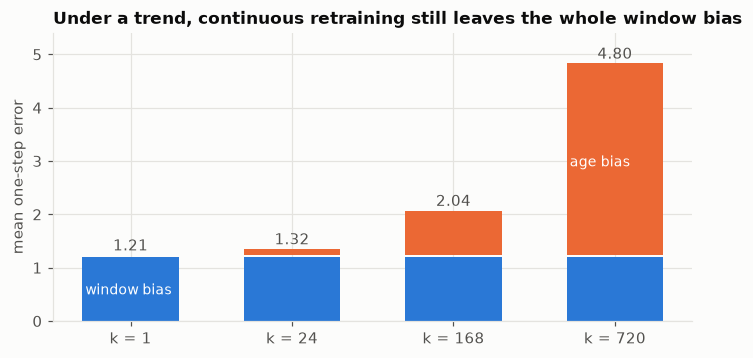

In [9]:
win = 0.01 * ((W - 1) / 2 + 1)
tr = {k: dict(theory=th, sim=sim, window=win, age=th - win) for k, (th, sim) in st["trend"].items()}
table([(f"k = {k}", r["theory"], r["sim"], r["window"], r["age"]) for k, r in tr.items()],
      ["cadence", "bias (theory)", "bias (simulation)", "window part", "age part"], fmt="{:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(len(tr))
wp = np.array([r["window"] for r in tr.values()]); ap = np.array([r["age"] for r in tr.values()])
ax.set_axisbelow(True)
ax.bar(x, wp, color=viz.BLUE, width=0.6)
ax.bar(x, ap, bottom=wp + 0.03, color=viz.ORANGE, width=0.6)
for i in x:
    ax.text(i, wp[i] + ap[i] + 0.12, f"{wp[i] + ap[i]:.2f}", ha="center", color=viz.TEXT_2)
ax.text(-0.28, 0.5, "window bias", color="white", fontsize=9)
ax.text(2.72, 2.9, "age bias", color="white", fontsize=9)
ax.set_xticks(x, [f"k = {k}" for k in tr])
ax.set_ylabel("mean one-step error"); ax.set_ylim(0, 5.4)
ax.set_title("Under a trend, continuous retraining still leaves the whole window bias")
export(fig, "trend_bias"); plt.show()

> **Takeaway.** Going from monthly to continuous retraining removes 75% of the bias (4.80 to 1.205), and every
> bit of the 1.205 that remains is window bias. The fix is a trend term or a weighted window, not a tighter cron.

## Summary

1. A window mean estimates the level **(w - 1)/2 steps in the past**; between refits the served number also
   ages. These are two additive error terms with two separate knobs.
2. The best window $w^*$ does not depend on the cadence. Tightening the cron never fixes a bad window.
3. A revision is jitter plus drift. At continuous cadence most of what is republished is noise, and how much
   depends on the window.
4. Rare retraining concentrates churn into large jumps; churn per step falls slowly and has no hard floor.
5. Under a trend, cadence removes the age bias only; the window bias stays.

All of this holds for the mean of a local level model. Block 2 shows that with abrupt level breaks the window
choice and the refit timing interact, which is exactly where the clean separation of section 3 stops.